# Telco Customers Customer Churn Predictive Analysis

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from scipy.stats import ttest_ind
from scipy.stats import chi2_contingency
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
import joblib
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, accuracy_score, f1_score
import warnings
warnings.filterwarnings('ignore')

In [3]:
data=pd.read_csv("/content/drive/MyDrive/Dataset_ATS_v2.csv")
print(data.head(5))

   gender  SeniorCitizen Dependents  tenure PhoneService MultipleLines  \
0  Female              0         No       1           No            No   
1    Male              0         No      41          Yes            No   
2  Female              0        Yes      52          Yes            No   
3  Female              0         No       1          Yes            No   
4    Male              0         No      67          Yes            No   

  InternetService        Contract  MonthlyCharges Churn  
0             DSL  Month-to-month              25   Yes  
1             DSL        One year              25    No  
2             DSL  Month-to-month              19    No  
3             DSL        One year              76   Yes  
4     Fiber optic  Month-to-month              51    No  


In [ ]:
print(data.shape)

(7043, 10)


In [ ]:
#find missing values
print(data.isna().sum())

gender             0
SeniorCitizen      0
Dependents         0
tenure             0
PhoneService       0
MultipleLines      0
InternetService    0
Contract           0
MonthlyCharges     0
Churn              0
dtype: int64


In [ ]:
# identify  data types and confirm columns
print(f'The data has {data.shape[0]} rows and {data.shape[1]} features')
print(data.dtypes)

The data has 7043 rows and 10 features
gender             object
SeniorCitizen       int64
Dependents         object
tenure              int64
PhoneService       object
MultipleLines      object
InternetService    object
Contract           object
MonthlyCharges      int64
Churn              object
dtype: object


In [ ]:
#descriptive summary of the numerical features
print(data.describe())

       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     7043.000000
mean        0.162147    32.371149       64.758768
std         0.368612    24.559481       30.091650
min         0.000000     0.000000       18.000000
25%         0.000000     9.000000       36.000000
50%         0.000000    29.000000       70.000000
75%         0.000000    55.000000       90.000000
max         1.000000    72.000000      119.000000


### 1. Univariate Analysis

#### Numerical Features Visualization

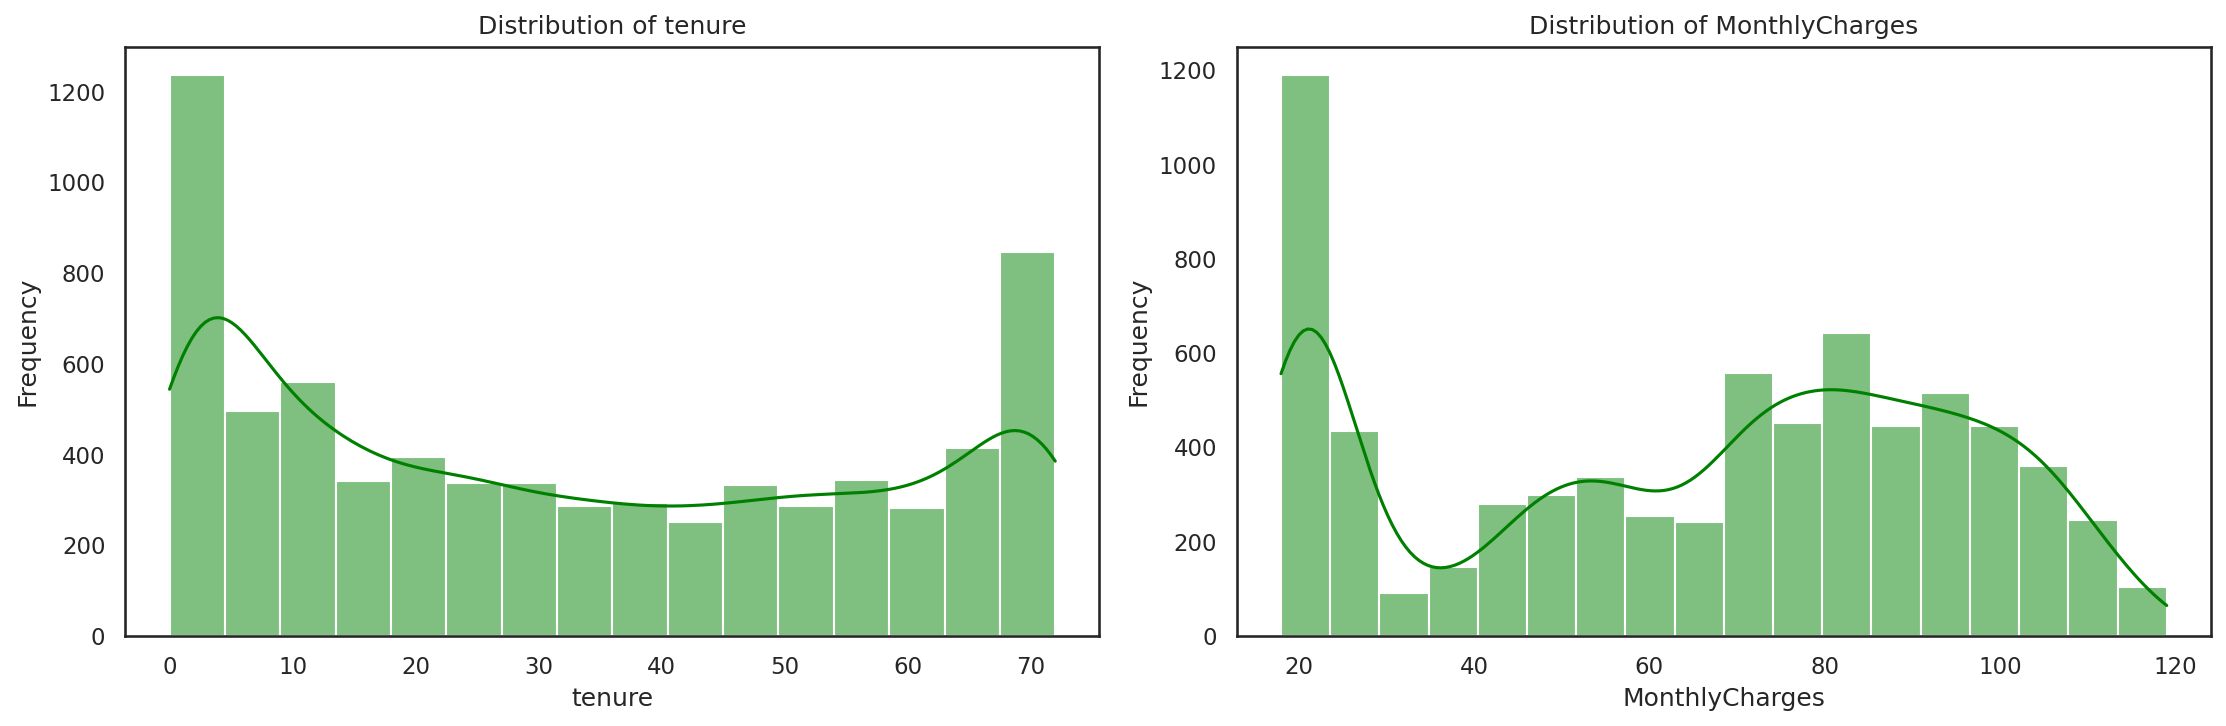

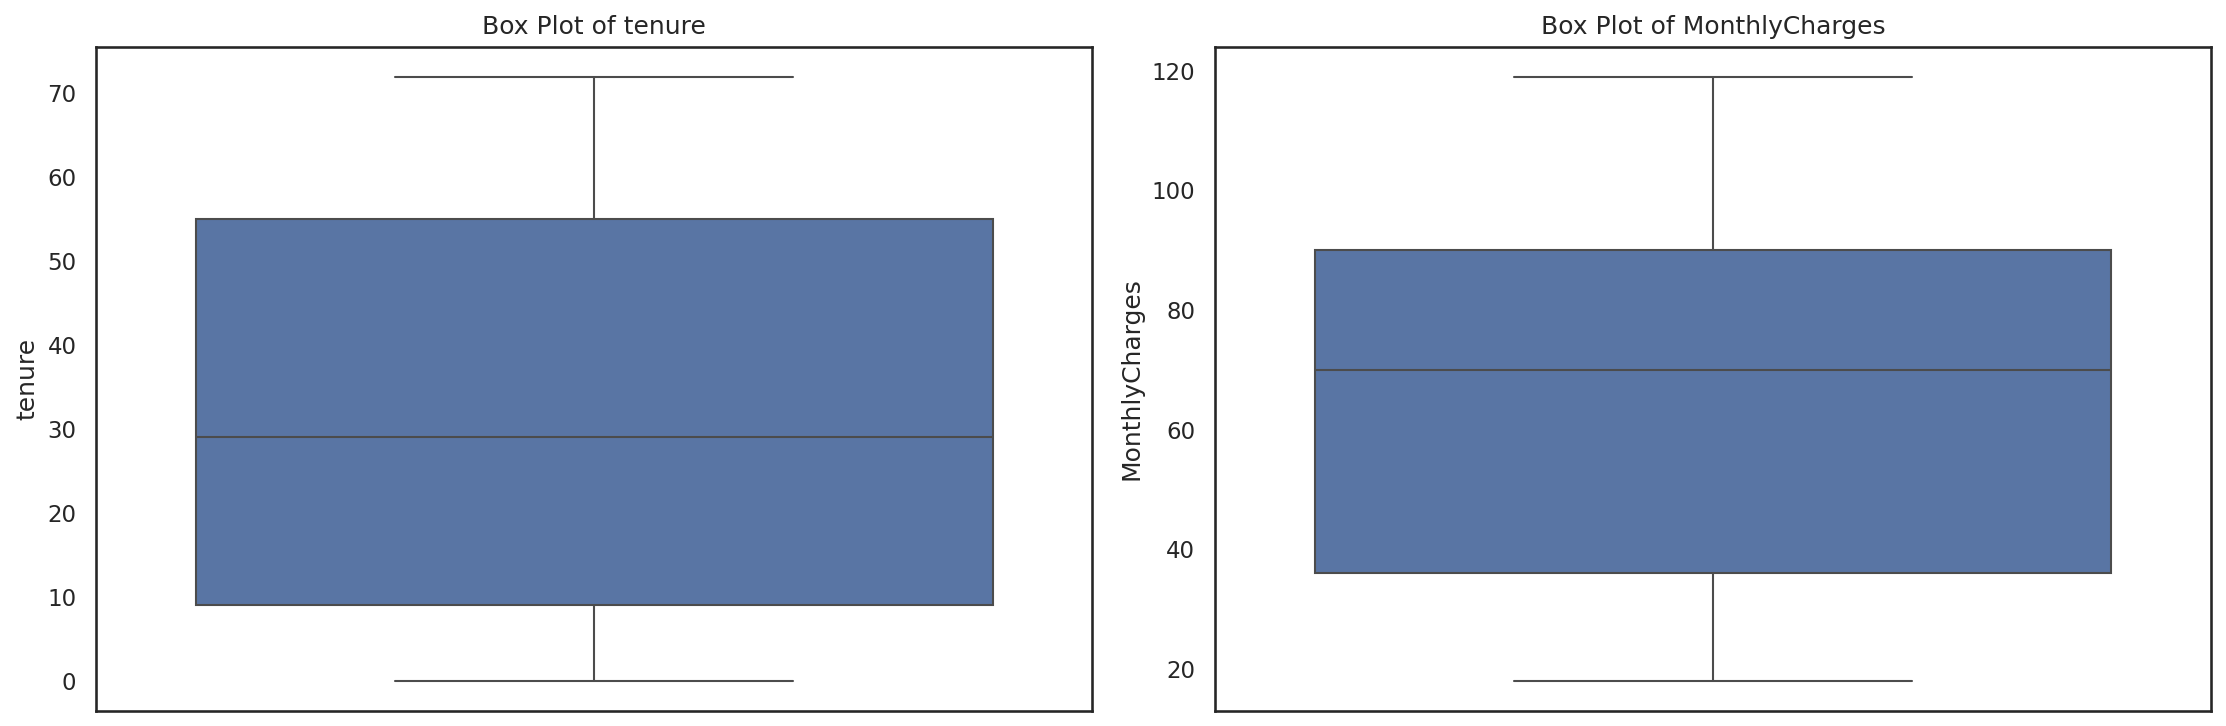

In [ ]:
numerical_features = ['tenure', 'MonthlyCharges']

plt.figure(figsize=(15, 5))
for i, feature in enumerate(numerical_features):
    plt.subplot(1, 2, i + 1)
    sns.histplot(data[feature], kde=True, color = 'green')
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 5))
for i, feature in enumerate(numerical_features):
    plt.subplot(1, 2, i + 1)
    sns.boxplot(y=data[feature])
    plt.title(f'Box Plot of {feature}')
    plt.ylabel(feature)
plt.tight_layout()
plt.show()

#### Categorical Features Visualization

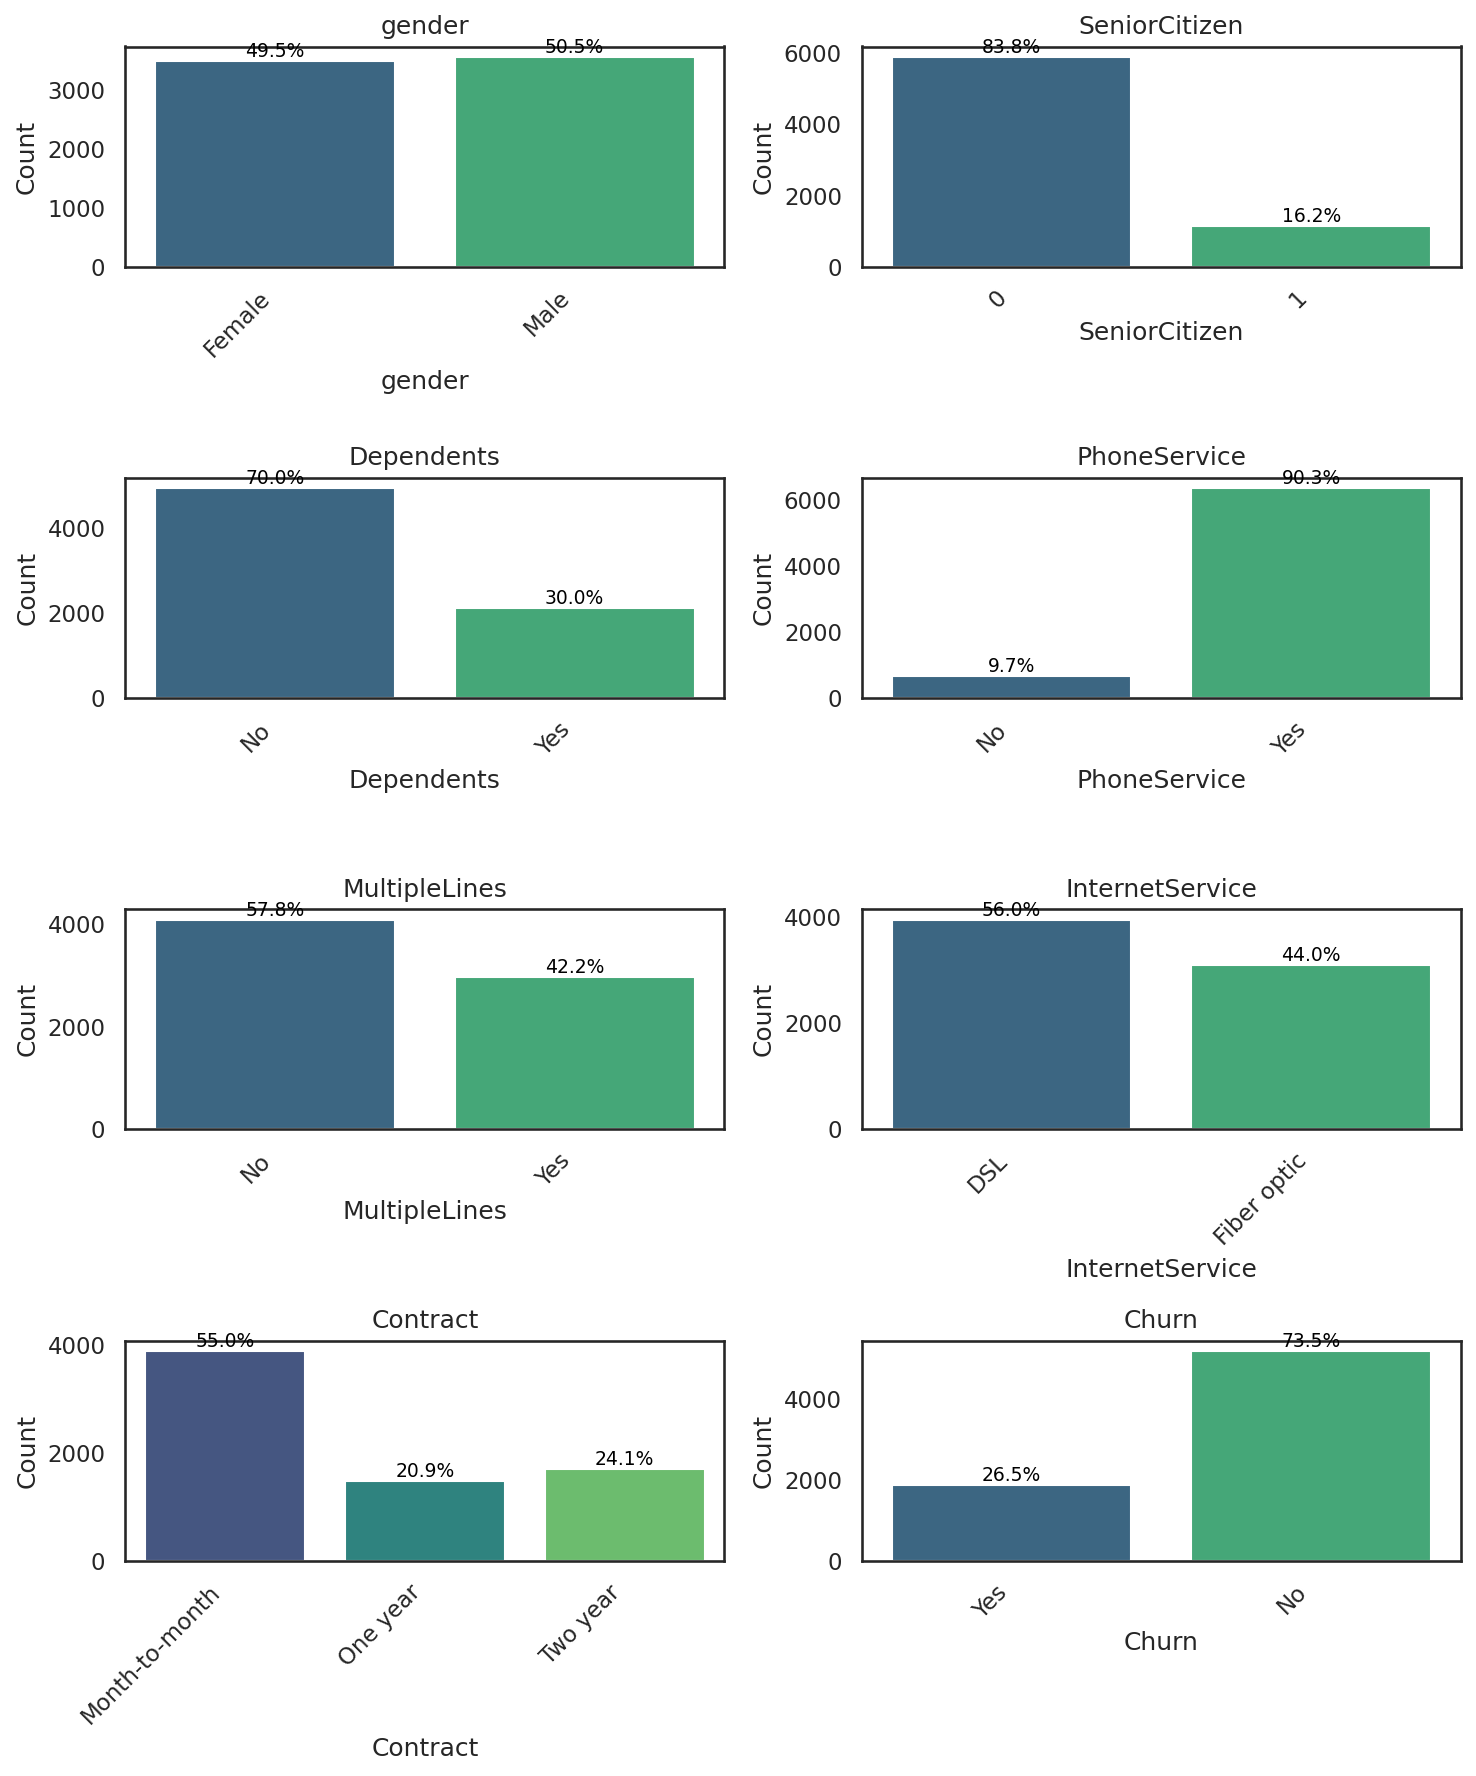

In [ ]:
categorical_features = ['gender', 'SeniorCitizen', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'Contract', 'Churn']

plt.figure(figsize=(10, 12))
for i, feature in enumerate(categorical_features):
    plt.subplot(4, 2, i + 1)
    ax = sns.countplot(x=data[feature], hue=data[feature], palette='viridis', legend=False)
    plt.title(f'{feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')

    # calculate percentages and add labels
    total = len(data[feature])
    for p in ax.patches:
        percentage = '{:.1f}%'.format(100 * p.get_height()/total)
        x = p.get_x() + p.get_width() / 2
        y = p.get_height()
        ax.annotate(percentage, (x, y), ha='center', va='bottom', fontsize=9, color='black')

plt.tight_layout()
plt.show()

### 2. Bivariate Analysis

How does the independent features relate to the target variable?

#### Numerical Features vs. Churn

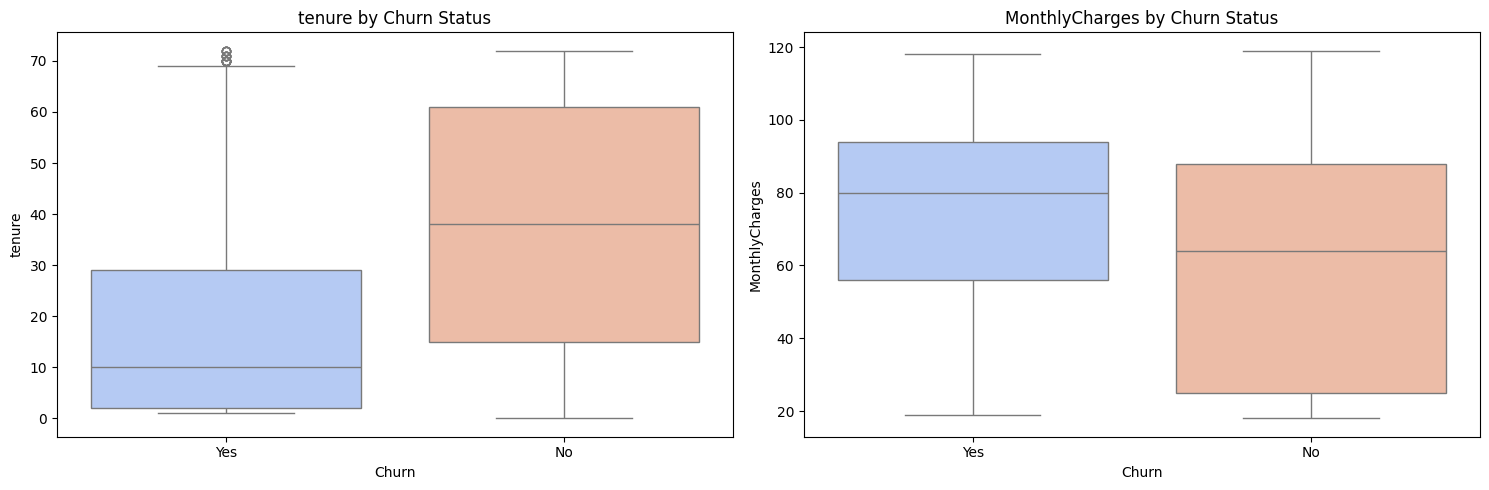

In [ ]:
plt.figure(figsize=(15, 5))
for i, feature in enumerate(numerical_features):
    plt.subplot(1, 2, i + 1)
    sns.boxplot(x='Churn', y=feature, data=data, palette='coolwarm')
    plt.title(f'{feature} by Churn Status')
    plt.xlabel('Churn')
    plt.ylabel(feature)
plt.tight_layout()
plt.show()

#### Independent Samples t-test (Numerical vs. Categorical)

In [ ]:
churn_yes = data[data['Churn'] == 'Yes']['MonthlyCharges']
churn_no = data[data['Churn'] == 'No']['MonthlyCharges']

t_statistic, p_value = ttest_ind(churn_yes, churn_no, equal_var=False) # Welch's t-test assuming unequal variances

print(f"T-statistic: {t_statistic:.2f}")
print(f"P-value: {p_value:.3f}")

if p_value < 0.05:
    print("Conclusion: There is a statistically significant difference in MonthlyCharges between churned and retained customers.")
else:
    print("Conclusion: There is no statistically significant difference in MonthlyCharges between churned and retained customers.")

T-statistic: 18.39
P-value: 0.000
Conclusion: There is a statistically significant difference in MonthlyCharges between churned and retained customers.


In [ ]:
churn_yes = data[data['Churn'] == 'Yes']['tenure']
churn_no = data[data['Churn'] == 'No']['tenure']

t_statistic, p_value = ttest_ind(
    churn_yes,
    churn_no,
    equal_var=False
)  # Welch's t-test assuming unequal variances

print(f"T-statistic: {t_statistic:.2f}")
print(f"P-value: {p_value:.3f}")

if p_value < 0.05:
    print("Conclusion: There is a statistically significant difference in tenure between churned and retained customers.")
else:
    print("Conclusion: There is no statistically significant difference in tenure between churned and retained customers.")

T-statistic: -34.82
P-value: 0.000
Conclusion: There is a statistically significant difference in tenure between churned and retained customers.


#### Categorical Features vs. Churn

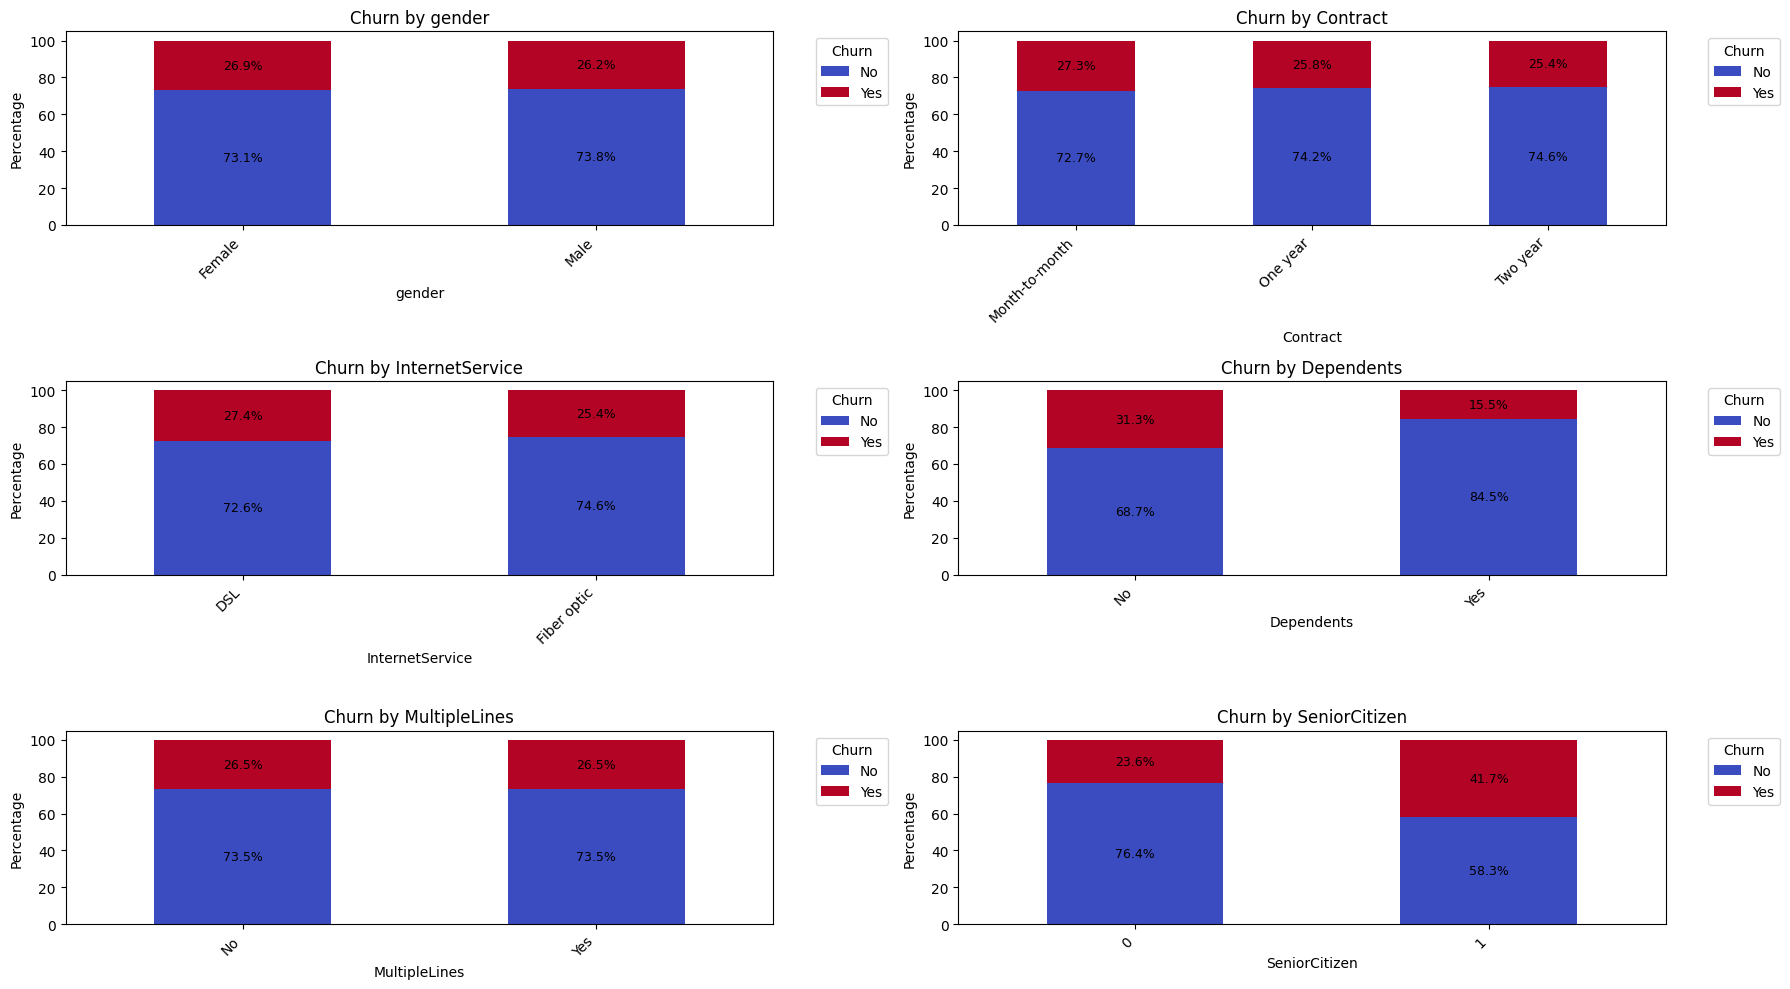

In [ ]:
features_to_compare = ['gender','Contract', 'InternetService', 'Dependents','MultipleLines', 'SeniorCitizen'] # Selected features

plt.figure(figsize=(20, 10))
for i, feature in enumerate(features_to_compare):
    plt.subplot(3, 2, i + 1)
    churn_by_feature = data.groupby([feature, 'Churn']).size().unstack(fill_value=0)

    # Calculate percentages
    churn_percentages = churn_by_feature.div(churn_by_feature.sum(axis=1), axis=0) * 100

    ax = churn_percentages.plot(kind='bar', stacked=True, ax=plt.gca(), cmap='coolwarm')
    plt.title(f'Churn by {feature}')
    plt.xlabel(feature)
    plt.ylabel('Percentage')
    plt.xticks(rotation=45, ha='right')
    plt.legend(title='Churn', bbox_to_anchor=(1.05, 1), loc='upper left')

    # Add percentage labels
    for container in ax.containers:
        for patch in container.patches:
            height = patch.get_height()
            width = patch.get_width()
            x, y = patch.get_xy()
            if height > 0: # Only label non-zero segments
                ax.text(x + width / 2, y + height / 2, f'{height:.1f}%',
                        ha='center', va='center', color='black', fontsize=9)

plt.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()

#### Chi-Square Test for Independence (Categorical vs. Categorical (Churn))

In [ ]:
def chi_square_test(data, categorical_variable, target='Churn'):
    # Create contingency table
    table = pd.crosstab(data[categorical_variable], data[target])

    # Chi-Square test
    chi2, p_value, dof, expected = chi2_contingency(table)

    print(f"\nChi-Square Test: {categorical_variable} vs {target}")
    print("-" * 50)
    print("Chi-Square Statistic:", chi2)
    print("P-value:", p_value)
    print("Degrees of Freedom:", dof)

    if p_value < 0.05:
        print("Conclusion: Significant association")
    else:
        print("Conclusion: No significant association")

    return chi2, p_value, dof, expected


chi_square_test(data, 'gender')
chi_square_test(data, 'Contract')
chi_square_test(data, 'InternetService')
chi_square_test(data, 'Dependents')
chi_square_test(data, 'MultipleLines')


Chi-Square Test: gender vs Churn
--------------------------------------------------
Chi-Square Statistic: 0.4840828822091383
P-value: 0.48657873605618596
Degrees of Freedom: 1
Conclusion: No significant association

Chi-Square Test: Contract vs Churn
--------------------------------------------------
Chi-Square Statistic: 2.84658271619807
P-value: 0.2409197573232328
Degrees of Freedom: 2
Conclusion: No significant association

Chi-Square Test: InternetService vs Churn
--------------------------------------------------
Chi-Square Statistic: 3.434779917987427
P-value: 0.06383708992967259
Degrees of Freedom: 1
Conclusion: No significant association

Chi-Square Test: Dependents vs Churn
--------------------------------------------------
Chi-Square Statistic: 189.12924940423474
P-value: 4.9249216612154196e-43
Degrees of Freedom: 1
Conclusion: Significant association

Chi-Square Test: MultipleLines vs Churn
--------------------------------------------------
Chi-Square Statistic: 0.0
P-value

(np.float64(0.0),
 np.float64(1.0),
 1,
 array([[2991.41388613, 1080.58611387],
        [2182.58611387,  788.41388613]]))

### 3. Correlation Analysis
Is there correlation between numerical features?

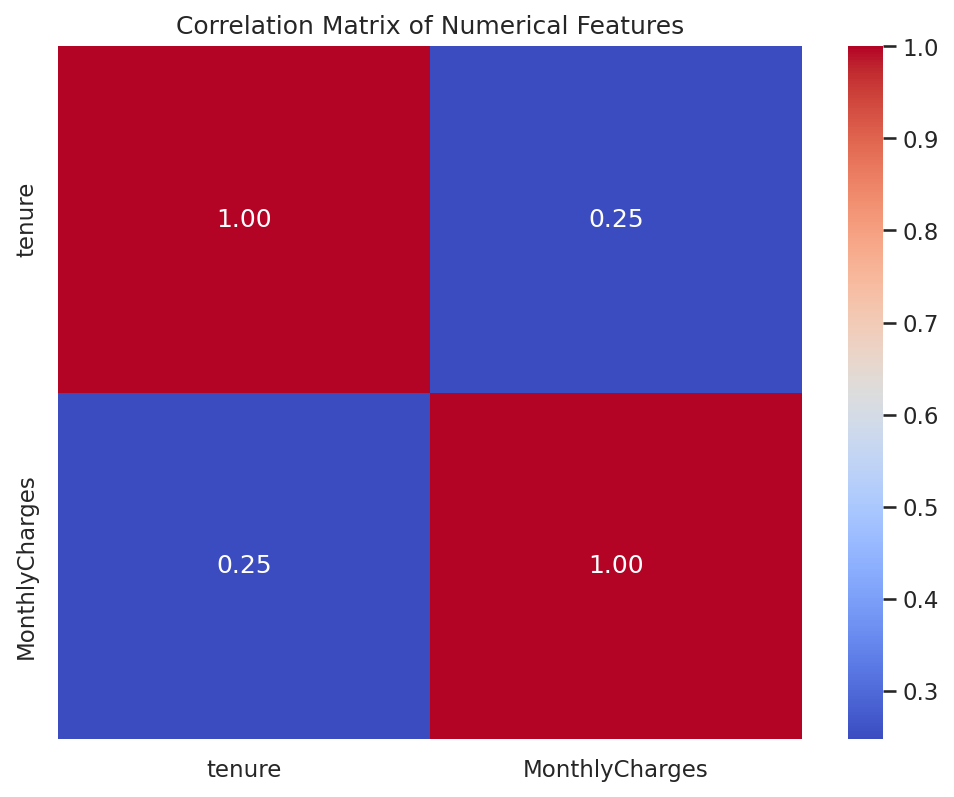

In [ ]:
correlation_matrix = data[numerical_features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix of Numerical Features')
plt.show()

### Derived Variables Analysis

Results from the univariate analysis show multimodal distributions for Monthly charges and tenure. That information gives us three groups for each of them.  

In [4]:
def analyze_chi2(df, feature_col, target_col='Churn'):
  """contingency table creation, Chi-Square test, and prints churn percentages."""
  print(f'-' * 50)
  print(f'{feature_col}')
  print(f'-' * 50)

  # ontingency table
  contingency_table = pd.crosstab(df[feature_col], df[target_col])
  #print('\n--- Contingency Table (Counts) ---')
  #print(contingency_table)

  # Chi-Square Test
  chi2, p_val, dof, expected = chi2_contingency(contingency_table)
  print(f'\nChi-Square Statistic: {chi2:.4f}')
  print(f'P-value: {p_val:.4e}')
  print(f'Degrees of Freedom: {dof}')

  if p_val < 0.05:
    print('Statistically significant association with Churn.')
  else:
    print('NO statistically significant association with Churn.')

  # churn rate breakdown %
  churn_percentages = (
      pd.crosstab(df[feature_col], df[target_col], normalize='index') * 100
  )
  print('\n Churn Rate by Group (%)')
  print(churn_percentages.round(2))
  print('\n')


# binning numerical variable into 3 groups

# tenure groups
data['Tenure_Groups'] = pd.cut(
    data['tenure'],
    bins=[-1, 12, 48, 72],
    labels=['Short (0-12m)', 'Mid-term (13-48m)', 'Long (49-72m)'],
)

# monthly harges groups
data['MonthlyCharges_Groups'] = pd.cut(
    data['MonthlyCharges'],
    bins=[0, 35, 70, 150],
    labels=['Low ($0-$35)', 'Medium ($35.01-$70)', 'High ($70.01+)'],
)

#Chi-Square analysis
analyze_chi2(data, 'Tenure_Groups')
analyze_chi2(data, 'MonthlyCharges_Groups')

--------------------------------------------------
Tenure_Groups
--------------------------------------------------

Chi-Square Statistic: 833.9514
P-value: 8.1238e-182
Degrees of Freedom: 2
Statistically significant association with Churn.

 Churn Rate by Group (%)
Churn                 No    Yes
Tenure_Groups                  
Short (0-12m)      52.56  47.44
Mid-term (13-48m)  76.36  23.64
Long (49-72m)      90.49   9.51


--------------------------------------------------
MonthlyCharges_Groups
--------------------------------------------------

Chi-Square Statistic: 346.3426
P-value: 6.2037e-76
Degrees of Freedom: 2
Statistically significant association with Churn.

 Churn Rate by Group (%)
Churn                     No    Yes
MonthlyCharges_Groups              
Low ($0-$35)           88.74  11.26
Medium ($35.01-$70)    75.24  24.76
High ($70.01+)         64.85  35.15




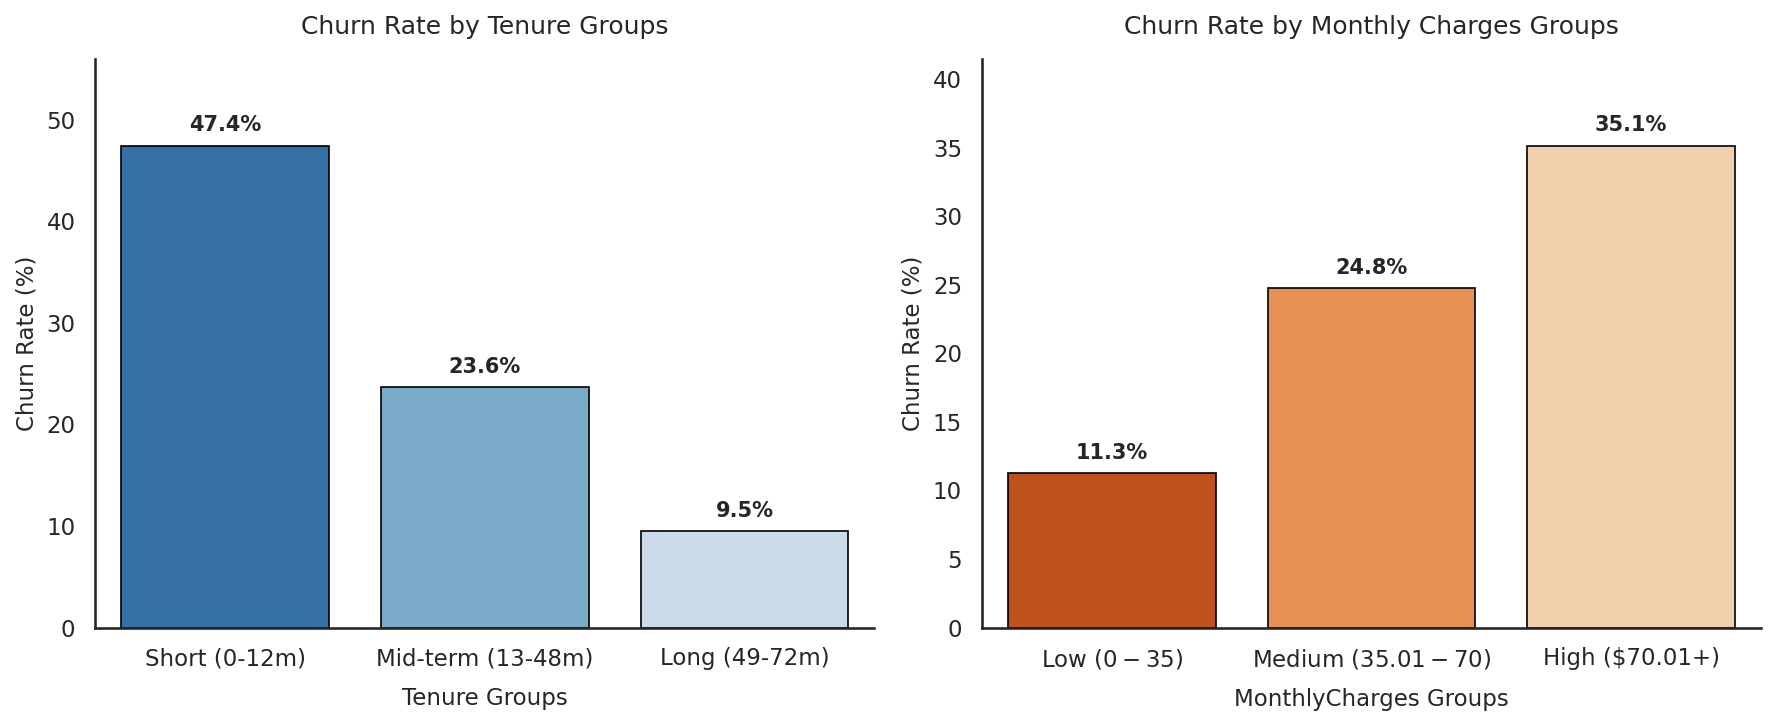

In [ ]:
sns.set_theme(style="white")
plt.rcParams.update({"font.family": "sans-serif", "figure.dpi": 150})


def plot_churn_subplot(
    df, group_col, title, ax, color_palette="Blues_r", target_col="Churn"
):
  """Plots churn percentage per group on a specific subplot axis."""
  # calculating churn rate%
  churn_df = (
      df.groupby(group_col, observed=False)[target_col]
      .value_counts(normalize=True)
      .unstack()
      .reset_index()
  )

  churn_df["Churn_Rate"] = churn_df["Yes"] * 100

  # barplot
  bars = sns.barplot(
      data=churn_df,
      x=group_col,
      y="Churn_Rate",
      palette=color_palette,
      edgecolor="black",
      linewidth=0.8,
      ax=ax,
  )

  # add data labels on top of bars
  for bar in bars.patches:
    height = bar.get_height()
    if height > 0:
      ax.annotate(
          f"{height:.1f}%",
          xy=(bar.get_x() + bar.get_width() / 2, height),
          xytext=(0, 5),
          textcoords="offset points",
          ha="center",
          va="bottom",
          fontsize=10,
          fontweight="bold",
      )

  # formatting subplot
  ax.set_title(title, fontsize=12, pad=12)
  ax.set_xlabel(group_col.replace("_", " "), fontsize=11, labelpad=8)
  ax.set_ylabel("Churn Rate (%)", fontsize=11)
  ax.set_ylim(0, max(churn_df["Churn_Rate"]) * 1.18)
  sns.despine(ax=ax, top=True, right=True, left=False)


# 1 x 2 grid layout
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# tenure groups
plot_churn_subplot(
    data,
    "Tenure_Groups",
    "Churn Rate by Tenure Groups",
    ax=axes[0],
    color_palette="Blues_r",
)

#Monthly Charges Groups
plot_churn_subplot(
    data,
    "MonthlyCharges_Groups",
    "Churn Rate by Monthly Charges Groups",
    ax=axes[1],
    color_palette="Oranges_r",
)

plt.tight_layout()
plt.show()

#  Data Preprocessing for Predictive Analysis and Simulation

First we create two parts of the whole dataset, the first part 10% hold-out data will be used to simulate a production scenario while the 90% portion will later be split into 80/20 parts for model training and evaluation

In [5]:
# Split the dataset with new variables into 90% and 10% portions randomly
portion_90, portion_10 = train_test_split(data, test_size=0.1, random_state=42)

print(f"90% Portion Shape: {portion_90.shape}")
print(f"10% Portion Shape: {portion_10.shape}")

print("\nFirst 3 rows of the 90% portion:")
display(portion_90.head(3))

print("\nFirst 3 rows of the 10% portion:")
display(portion_10.head(3))

90% Portion Shape: (6338, 12)
10% Portion Shape: (705, 12)

First 3 rows of the 90% portion:


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn,Tenure_Groups,MonthlyCharges_Groups
1554,Male,0,No,11,Yes,No,DSL,Month-to-month,69,No,Short (0-12m),Medium ($35.01-$70)
4817,Female,0,No,5,Yes,No,DSL,Month-to-month,76,No,Short (0-12m),High ($70.01+)
5957,Female,0,No,63,Yes,No,Fiber optic,Month-to-month,21,No,Long (49-72m),Low ($0-$35)



First 3 rows of the 10% portion:


,gender,SeniorCitizen,Dependents,tenure,PhoneService,MultipleLines,InternetService,Contract,MonthlyCharges,Churn,Tenure_Groups,MonthlyCharges_Groups
185,Male,0,Yes,70,Yes,No,DSL,Month-to-month,25,No,Long (49-72m),Low ($0-$35)
2715,Female,0,No,5,Yes,Yes,DSL,Month-to-month,44,No,Short (0-12m),Medium ($35.01-$70)
3825,Male,0,Yes,72,Yes,No,DSL,Two year,25,No,Long (49-72m),Low ($0-$35)


# Feature Selection



In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# feature columns and target
features = ['Dependents', 'Tenure_Groups', 'MonthlyCharges_Groups']
target = 'Churn'

# Separate features (X) and target (y) from the 90% portion
X_90 = portion_90[features]
y_90 = portion_90[target].map({'Yes': 1, 'No': 0})

# Create a preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), features)
    ]
)

# overall feature pipeline
pipeline = Pipeline(steps=[('preprocessor', preprocessor)])

# split the 90% portion into 80% train and 20% test sets
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_90, y_90, test_size=0.2, random_state=42, stratify=y_90
)

# fit the pipeline on training data and transform both train and test sets
X_train_encoded = pipeline.fit_transform(X_train_raw)
X_test_encoded = pipeline.transform(X_test_raw)

# get feature names from encoder for clean DataFrame structures
encoded_cols = pipeline.named_steps['preprocessor'].transformers_[0][1].get_feature_names_out(features)

X_train_df = pd.DataFrame(X_train_encoded, columns=encoded_cols, index=X_train_raw.index)
X_test_df = pd.DataFrame(X_test_encoded, columns=encoded_cols, index=X_test_raw.index)

# apply SMOTE to address class imbalance on the training dataset
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_df, y_train)

# Print information and verify dimensions
print("Original Training Features Shape:", X_train_df.shape)
print("Resampled Training Features Shape (SMOTE):", X_train_resampled.shape)
print("Testing Features Shape:", X_test_df.shape)
print("\nOriginal Target Class Distribution:\n", y_train.value_counts(normalize=True))
print("\nResampled Target Class Distribution (SMOTE):\n", pd.Series(y_train_resampled).value_counts(normalize=True))

print("\nFirst 3 rows of processed and resampled training features:")
display(X_train_resampled.head(3))

Original Training Features Shape: (5070, 8)
Resampled Training Features Shape (SMOTE): (7420, 8)
Testing Features Shape: (1268, 8)

Original Target Class Distribution:
 Churn
0    0.731755
1    0.268245
Name: proportion, dtype: float64

Resampled Target Class Distribution (SMOTE):
 Churn
0    0.5
1    0.5
Name: proportion, dtype: float64

First 3 rows of processed and resampled training features:


,Dependents_No,Dependents_Yes,Tenure_Groups_Long (49-72m),Tenure_Groups_Mid-term (13-48m),Tenure_Groups_Short (0-12m),MonthlyCharges_Groups_High ($70.01+),MonthlyCharges_Groups_Low ($0-$35),MonthlyCharges_Groups_Medium ($35.01-$70)
0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
1,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


# ANN Model Architecture

In [9]:
#  MLP Classifier with optimized settings for convergence
# Note on Parameter Optimization:
# 1. hidden_layer_sizes=(32, 16): Funnel structure starting with 32 units down to 16 to distill representations without overfitting.
# 2. early_stopping=True & validation_fraction=0.1: Monitors validation loss and halts training when generalization performance plateaus.
# 3. solver='adam': Adaptive learning rate optimizer suitable for fast convergence and handling local minima in tabular data structures.

from sklearn.neural_network import MLPClassifier

ann_model = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    solver='adam',
    max_iter=300,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.1
)

def predict_with_threshold(model, X, threshold=0.5):
    """
    Predicts classes using a custom probability threshold.
    helps identify more potential churners (improving Recall).
    """
    # probability of class 1 (Churn)
    probs = model.predict_proba(X)[:, 1]
    # Apply the custom threshold
    return (probs >= threshold).astype(int)

# Train ANN on the SMOTE-Resampled Balanced Dataset

Model training on SMOTE-balanced dataset completed successfully!


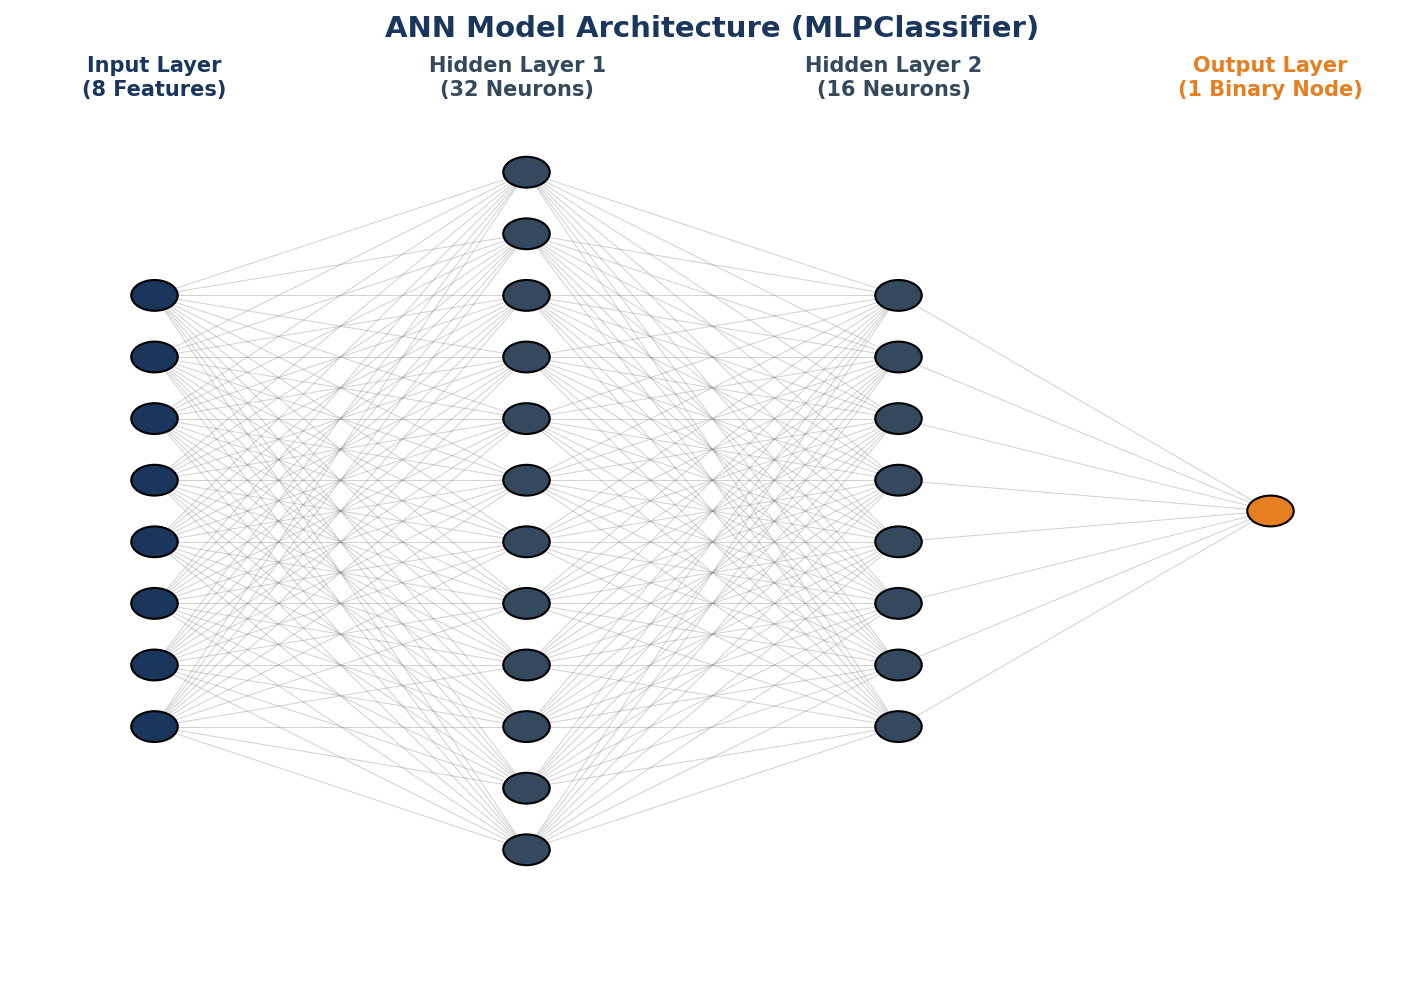

In [12]:

# train model
ann_model.fit(X_train_resampled, y_train_resampled)
print("Model training on SMOTE-balanced dataset completed successfully!")

# Setup custom neural network visualization
def draw_neural_network(ax, left, right, bottom, top, layer_sizes):
    '''
    Draws a neural network schema using matplotlib.
    '''
    v_spacing = (top - bottom)/float(max(layer_sizes))
    h_spacing = (right - left)/float(len(layer_sizes) - 1)

    # Nodes
    for n, layer_size in enumerate(layer_sizes):
        layer_top = v_spacing*(layer_size - 1)/2. + (top + bottom)/2.
        for m in range(layer_size):
            circle = plt.Circle((n*h_spacing + left, layer_top - m*v_spacing), v_spacing/4.,
                                color='#1B365D' if n == 0 else ('#E67E22' if n == len(layer_sizes)-1 else '#34495E'),
                                ec='k', zorder=4)
            ax.add_artist(circle)

    # Edges
    for n, (layer_size_a, layer_size_b) in enumerate(zip(layer_sizes[:-1], layer_sizes[1:])):
        layer_top_a = v_spacing*(layer_size_a - 1)/2. + (top + bottom)/2.
        layer_top_b = v_spacing*(layer_size_b - 1)/2. + (top + bottom)/2.
        for m in range(layer_size_a):
            for o in range(layer_size_b):
                line = plt.Line2D([n*h_spacing + left, (n + 1)*h_spacing + left],
                                  [layer_top_a - m*v_spacing, layer_top_b - o*v_spacing], c='gray', alpha=0.35, lw=0.5)
                ax.add_artist(line)

# figure parameters
fig = plt.figure(figsize=(12, 8), dpi=150)
ax = fig.gca()
ax.axis('off')

# Layer dimensions: 8 input features -> 32 hidden (scaled to 12 for clean visibility) -> 16 hidden (scaled to 8) -> 1 output
scaled_layer_sizes = [8, 12, 8, 1]

draw_neural_network(ax, .1, .9, .1, .9, scaled_layer_sizes)
plt.title("ANN Model Architecture (MLPClassifier)", fontsize=14, fontweight='bold', color='#1B365D')

# Annotations
plt.text(0.1, 0.95, "Input Layer\n(8 Features)", ha='center', fontweight='bold', color='#1B365D')
plt.text(0.36, 0.95, "Hidden Layer 1\n(32 Neurons)", ha='center', fontweight='bold', color='#34495E')
plt.text(0.63, 0.95, "Hidden Layer 2\n(16 Neurons)", ha='center', fontweight='bold', color='#34495E')
plt.text(0.9, 0.95, "Output Layer\n(1 Binary Node)", ha='center', fontweight='bold', color='#E67E22')

plt.show()

# Save Preprocessing Pipeline & Model for Production Simulation



In [13]:
joblib.dump(pipeline, 'preprocessing_pipeline.joblib')
joblib.dump(ann_model, 'ann_churn_model.joblib')
print("Preprocessing pipeline saved as 'preprocessing_pipeline.joblib'")
print("ANN model saved as 'ann_churn_model.joblib'")

Preprocessing pipeline saved as 'preprocessing_pipeline.joblib'
ANN model saved as 'ann_churn_model.joblib'


# Predict Customer Churn and Calculate Performance Metrics

In [14]:
y_pred = ann_model.predict(X_test_df)
y_prob = ann_model.predict_proba(X_test_df)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
print(f"Overall Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Overall Accuracy: 0.6798

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.64      0.75       928
           1       0.45      0.79      0.57       340

    accuracy                           0.68      1268
   macro avg       0.67      0.71      0.66      1268
weighted avg       0.77      0.68      0.70      1268



# Evaluation Plots

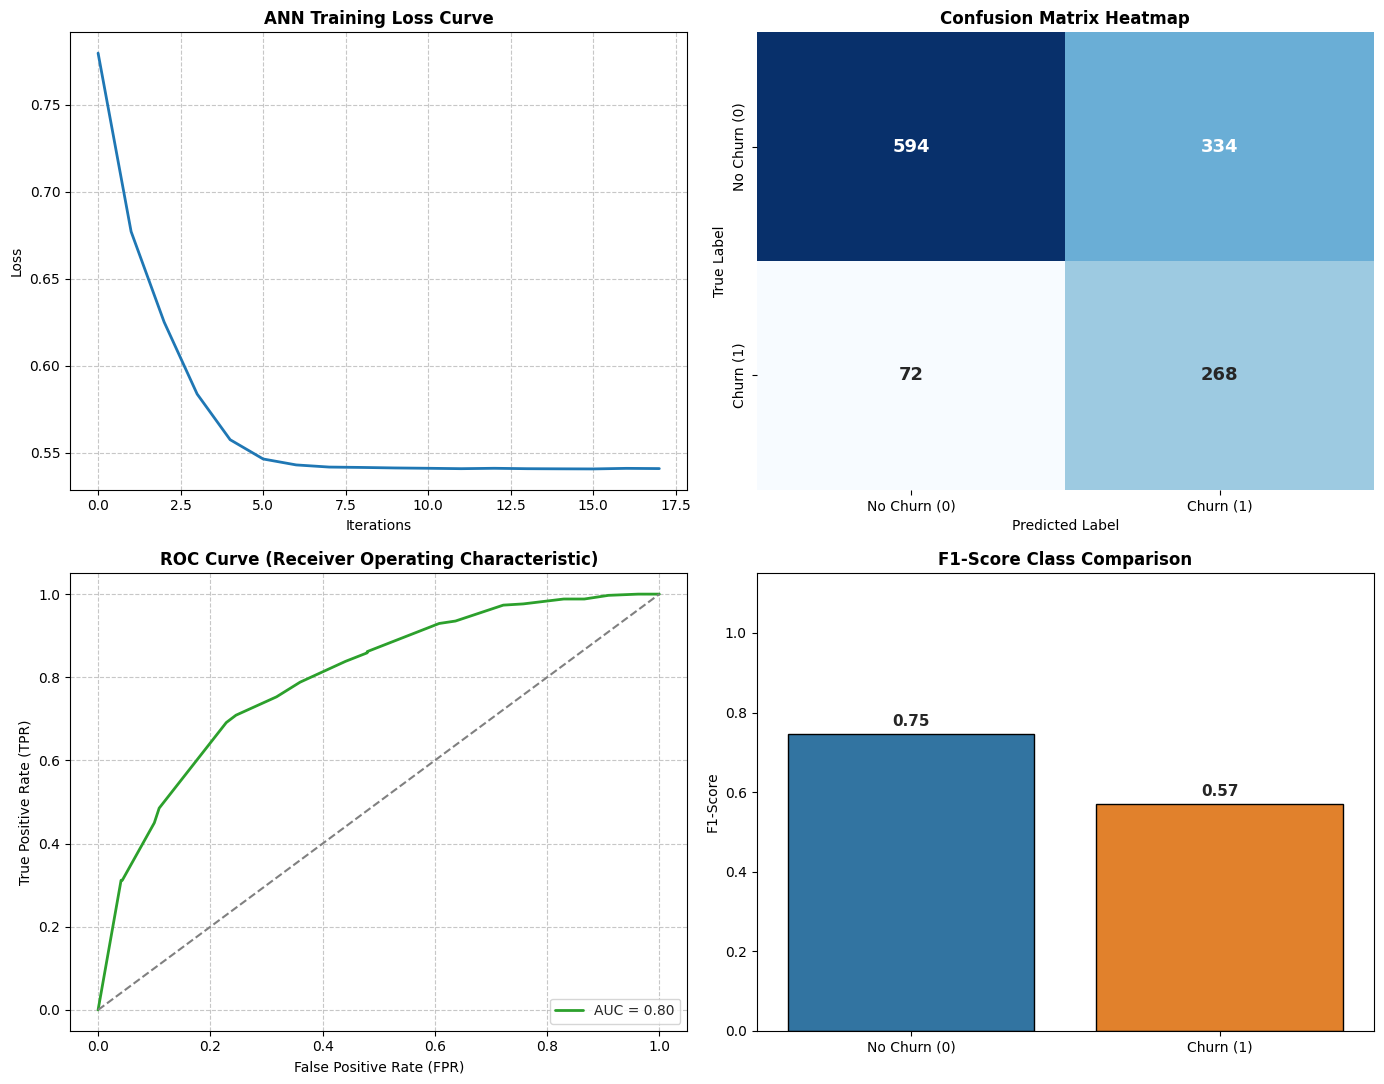

In [15]:


# Compute metric details
f1_no_churn = f1_score(y_test, y_pred, pos_label=0, zero_division=0)
f1_churn = f1_score(y_test, y_pred, pos_label=1, zero_division=0)
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

fig, axes = plt.subplots(2, 2, figsize=(14, 11))
sns.set_theme(style="whitegrid")

# 1. Loss Curve
axes[0, 0].plot(ann_model.loss_curve_, color='#1f77b4', lw=2)
axes[0, 0].set_title("ANN Training Loss Curve", fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel("Iterations")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].grid(True, linestyle='--', alpha=0.7)

# 2. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0, 1], cbar=False,
            annot_kws={"size": 13, "weight": "bold"})
axes[0, 1].set_title("Confusion Matrix Heatmap", fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel("Predicted Label")
axes[0, 1].set_ylabel("True Label")
axes[0, 1].set_xticklabels(['No Churn (0)', 'Churn (1)'])
axes[0, 1].set_yticklabels(['No Churn (0)', 'Churn (1)'])

# 3. ROC Curve
axes[1, 0].plot(fpr, tpr, color='#2ca02c', lw=2, label=f'AUC = {roc_auc:.2f}')
axes[1, 0].plot([0, 1], [0, 1], color='grey', linestyle='--')
axes[1, 0].set_title("ROC Curve (Receiver Operating Characteristic)", fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel("False Positive Rate (FPR)")
axes[1, 0].set_ylabel("True Positive Rate (TPR)")
axes[1, 0].legend(loc="lower right", fontsize=10)
axes[1, 0].grid(True, linestyle='--', alpha=0.7)

# 4. F1-Score Comparison
classes = ['No Churn (0)', 'Churn (1)']
f1_values = [f1_no_churn, f1_churn]
sns.barplot(x=classes, y=f1_values, palette=['#1f77b4', '#ff7f0e'], ax=axes[1, 1], edgecolor='black')
axes[1, 1].set_title("F1-Score Class Comparison", fontsize=12, fontweight='bold')
axes[1, 1].set_ylabel("F1-Score")
axes[1, 1].set_ylim(0, 1.15)
for index, val in enumerate(f1_values):
    axes[1, 1].text(index, val + 0.02, f"{val:.2f}", ha='center', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

# Production Simulation (Inference on 10% Hold-out Set)

Loaded preprocessing pipeline and ANN model from disk successfully!

Hold-out Set (10% Portion) Size: 705 records
Simulated Production Accuracy: 0.6482

Hold-out Set Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.61      0.73       536
           1       0.38      0.76      0.51       169

    accuracy                           0.65       705
   macro avg       0.64      0.69      0.62       705
weighted avg       0.77      0.65      0.67       705



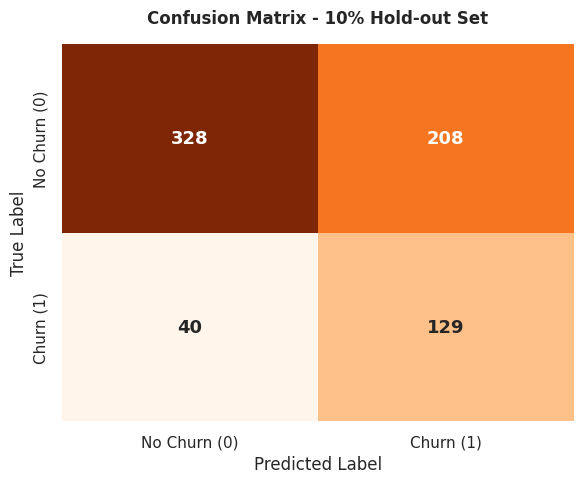

In [18]:
# load the production data preprocessing pipeline and model
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

loaded_pipeline = joblib.load('preprocessing_pipeline.joblib')
loaded_model = joblib.load('ann_churn_model.joblib')
print("Loaded preprocessing pipeline and ANN model from disk successfully!")

# extract features and target from the  10% hold-out set
X_holdout_raw = portion_10[['Dependents', 'Tenure_Groups', 'MonthlyCharges_Groups']]
y_holdout = portion_10['Churn'].map({'Yes': 1, 'No': 0})

# preprocess the raw hold-out features using the loaded pipeline
X_holdout_encoded = loaded_pipeline.transform(X_holdout_raw)
feature_names = loaded_pipeline.named_steps['preprocessor'].transformers_[0][1].get_feature_names_out()
X_holdout_df = pd.DataFrame(X_holdout_encoded, columns=feature_names, index=X_holdout_raw.index)

# perform inference with the loaded ANN model
holdout_predictions = loaded_model.predict(X_holdout_df)

# results evaluation
holdout_accuracy = accuracy_score(y_holdout, holdout_predictions)
print(f"\nHold-out Set (10% Portion) Size: {len(X_holdout_raw)} records")
print(f"Simulated Production Accuracy: {holdout_accuracy:.4f}\n")
print("Hold-out Set Classification Report:")
print(classification_report(y_holdout, holdout_predictions, zero_division=0))

# Plot Confusion Matrix for Hold-out Set
plt.figure(figsize=(6, 5), dpi=100)
cm_holdout = confusion_matrix(y_holdout, holdout_predictions)
sns.heatmap(cm_holdout, annot=True, fmt='d', cmap='Oranges', cbar=False,
            annot_kws={"size": 13, "weight": "bold"})
plt.title("Confusion Matrix - 10% Hold-out Set", fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.gca().set_xticklabels(['No Churn (0)', 'Churn (1)'])
plt.gca().set_yticklabels(['No Churn (0)', 'Churn (1)'])
plt.tight_layout()
plt.show()

In [17]:
# map numeric predictions back to original label format ('Yes' / 'No')
predicted_labels = pd.Series(holdout_predictions, index=portion_10.index).map({1: 'Yes', 0: 'No'})

# Create a copy of the hold-out portion
annotated_holdout = portion_10.copy()

# insert the predictions
annotated_holdout['Predicted_Churn'] = predicted_labels

# save the annotated hold-out dataset to CSV
output_path = '/content/holdout_predictions_output.csv'
annotated_holdout.to_csv(output_path, index=False)
print(f"Annotated hold-out dataset saved successfully to: {output_path}")

display(annotated_holdout[['gender', 'Dependents', 'tenure', 'MonthlyCharges', 'Churn', 'Predicted_Churn']].head(10))

Annotated hold-out dataset saved successfully to: /content/holdout_predictions_output.csv


,gender,Dependents,tenure,MonthlyCharges,Churn,Predicted_Churn
185,Male,Yes,70,25,No,No
2715,Female,No,5,44,No,Yes
3825,Male,Yes,72,25,No,No
1807,Female,No,3,20,No,Yes
132,Male,Yes,21,104,Yes,Yes
1263,Male,Yes,23,20,No,No
3732,Female,Yes,10,91,No,Yes
1672,Female,No,10,76,No,Yes
811,Female,Yes,23,82,No,Yes
2526,Female,Yes,40,85,Yes,Yes


A data analytics and machine learning project focused on customer churn prediction in the telecommunications industry. Using a dataset of 7,043 customers, the project Artificial Neural Network (ANN) built with Scikit-learn's MLPClassifier to predict customer churn.